# NB04 · Rating migration

**Project:** multiyear-credit-engine
**Job requirement covered:** Rating migration dynamics; default probabilities.
**Engine module:** `creditengine.models.migration`
**Assumptions:** A-01
**Theory:** Bluhm §6.1, §6.3.1–6.3.4, §8.4.1; CreditMetrics (1997); Lando (2004)
**Status:** ✅ Developed — every function is built from scratch in this notebook

## Objective

How does the engine move each bond from one rating to the next every year — how are the migration thresholds set, how do they behave over many years and through the credit cycle, and do they reproduce published multi-year default rates?

## Results at a glance

| Question | Answer |
|---|---|
| How are thresholds set? | Cut a standard normal so each slice has the probability of one rating move. BBB defaults when its asset return falls below **−2.99** |
| Which one moves? | The **thresholds are fixed**; the **asset return moves** each year with the credit cycle |
| Does simulation reproduce the matrix? | Yes — 1,000,000 draws per rating match every cell within **0.1 percentage points** |
| How bad is a bad year? | At $Z = -2$ the BBB one-year PD rises from 0.14% (long-run) to **1.03%**, and **18%** of BBB issuers are downgraded instead of 4% |
| Does $P^n$ match published multi-year defaults? | Up to 5 years for investment grade (BBB: 1.23% vs 1.33%); beyond that, and for speculative grade, too high (B 10 years: 39.5% vs 21.7%) |
| Fix | A time-varying generator (Bluhm–Overbeck) fits the published curves: B 10 years **21.6%** vs 21.7%, BBB **2.77%** vs 2.78% |

## Key terms and symbols

| Symbol | Meaning |
|---|---|
| $k$ | Rating at the start of the year |
| $j, l$ | Possible ratings at the end of the year, ordered AAA (best) … CCC/C, D (default, worst) |
| $m_{k,l}$ | One-year probability of moving from $k$ to $l$ (S&P matrix, NR removed — NB01) |
| $M$ | The 8 × 8 one-year transition matrix |
| $\Phi, \Phi^{-1}$ | Standard normal probability and its inverse |
| $c_{k,j}$ | **Threshold** (cut-off): an issuer rated $k$ ends at $j$ or worse when its asset return falls below $c_{k,j}$ |
| $A$ | Issuer's asset return over the year, standard normal |
| $Z$ | Credit-cycle factor shared by all issuers (low = bad year) |
| $\rho$ | Asset correlation: how much each issuer depends on $Z$ |
| $Q$ | Generator: migration *rates* per unit of time, with $M = e^{Q}$ |

## Inputs

| Data | File | Used for |
|---|---|---|
| One-year transition matrix (from NB01) | `data/processed/transition_matrix_1y.parquet` | thresholds, $P^n$, generator |
| S&P average cumulative default rates, 1–15 years (local only) | `data/external/cumulative_default_rates.csv` | comparison with $P^n$ (V-03) |
| Asset correlation by rating | Basel IRB corporate formula (A-02); NB03 calibrates the cycle | cycle-conditional matrices |

## Outputs

- `data/processed/migration_thresholds.parquet` — cut-offs $c_{k,j}$ for every rating
- `data/processed/generator_matrix.parquet` — generator $Q$
- `reports/figures/migration_thresholds_bbb.png` — the BBB cut-offs on the normal curve
- `reports/figures/migration_cumulative_pd.png` — multi-year cumulative PD by rating: matrix, time-varying fit, published

## 0. Setup

The simulation check in section 1 uses random draws, so the seed is fixed for repeatable results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import expm, logm
from scipy.optimize import least_squares
from scipy.stats import norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]
STATES = RATINGS + ["D"]
rng = np.random.default_rng(2026)
pd.set_option("display.float_format", "{:,.3f}".format)

M = pd.read_parquet(DATA / "processed" / "transition_matrix_1y.parquet").loc[STATES, STATES]
observed = pd.read_csv(DATA / "external" / "cumulative_default_rates.csv", index_col=0).loc[RATINGS] / 100
observed.columns = observed.columns.astype(int)
print(M.shape, observed.shape)
(100 * M).round(2)

(8, 8) (7, 15)


,AAA,AA,A,BBB,BB,B,CCC/C,D
from,,,,,,,,
AAA,90.060,9.190,0.530,0.030,0.100,0.030,0.050,0.000
AA,0.460,91.200,7.740,0.450,0.050,0.060,0.020,0.020
A,0.020,1.580,93.310,4.710,0.230,0.090,0.010,0.040
BBB,0.000,0.070,3.260,92.720,3.310,0.400,0.100,0.140
BB,0.010,0.020,0.110,4.830,87.110,6.770,0.540,0.610
B,0.000,0.020,0.060,0.160,5.070,85.960,5.440,3.280
CCC/C,0.000,0.000,0.080,0.140,0.450,15.430,53.080,30.810
D,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.000


## 1. Thresholds from matrix rows (CreditMetrics)

**Idea:** each year an issuer gets one standard-normal asset return $A$. Cut the normal curve into slices — one per possible rating — so that each slice has exactly the probability of that move in the matrix. Where $A$ lands decides next year's rating.

$$c_{k,j} = \Phi^{-1}\Big(\sum_{l \ge j} m_{k,l}\Big)$$

The cut-off for "rating $j$ or worse" is the normal quantile of the probability of ending at $j$ or worse.

$$\text{next rating} = j \quad \text{when} \quad c_{k,j+1} < A \le c_{k,j}, \qquad c_{k,\text{AAA}} = +\infty, \quad c_{k,\text{below D}} = -\infty$$

Default is the lowest slice: $A \le c_{k,D} = \Phi^{-1}(PD_k)$.

**Which one moves?** The cut-offs are fixed by history. $A$ moves every year — and in section 4 it carries the shared credit cycle, so a bad year pushes many issuers through the lower cut-offs together.

### 1.1 Probability of ending at each rating *or worse*

In [2]:
tail = M.iloc[:, ::-1].cumsum(axis=1).iloc[:, ::-1]      # sum over l >= j, row by row
(100 * tail.loc[RATINGS]).round(3)

,AAA,AA,A,BBB,BB,B,CCC/C,D
from,,,,,,,,
AAA,100.000,9.937,0.743,0.217,0.186,0.083,0.052,0.000
AA,100.000,99.543,8.340,0.602,0.156,0.104,0.042,0.021
A,100.000,99.979,98.396,5.084,0.375,0.146,0.052,0.042
BBB,100.000,100.000,99.926,96.668,3.947,0.637,0.233,0.138
BB,100.000,99.989,99.967,99.856,95.031,7.917,1.148,0.607
B,100.000,100.000,99.977,99.920,99.760,94.692,8.728,3.283
CCC/C,100.000,100.000,100.000,99.917,99.776,99.328,83.898,30.813


**How to read it:** row BBB, column BB = 3.95%: the chance a BBB issuer ends the year at BB or worse (BB, B, CCC/C or D). Column AAA is always 100%.

### 1.2 The cut-offs

In [3]:
def thresholds(M):
    # c[k, j] = inverse normal of P(end at j or worse); first column +inf (anything above is AAA)
    tail = np.cumsum(M[:, ::-1], axis=1)[:, ::-1]
    c = norm.ppf(np.clip(tail, 0.0, 1.0))
    c[:, 0] = np.inf
    return c

C = pd.DataFrame(thresholds(M.to_numpy()), index=STATES, columns=STATES)
C.loc[RATINGS, STATES[1:]]

,AA,A,BBB,BB,B,CCC/C,D
AAA,-1.285,-2.436,-2.853,-2.901,-3.147,-3.282,-inf
AA,2.607,-1.383,-2.511,-2.956,-3.079,-3.342,-3.530
A,3.529,2.143,-1.637,-2.674,-2.976,-3.279,-3.341
BBB,inf,3.177,1.834,-1.757,-2.491,-2.829,-2.993
BB,3.694,3.405,2.981,1.648,-1.411,-2.274,-2.508
B,inf,3.504,3.156,2.820,1.616,-1.358,-1.841
CCC/C,inf,inf,3.147,2.842,2.472,0.990,-0.501


**How to read it:** each column is the cut-off for ending at that rating or worse. For BBB: above +1.83 it is upgraded to A (above +3.18 to AA); below −1.76 it falls to BB or worse; below **−2.99** it defaults. A higher starting rating has its default cut-off further down (A: −3.34), so it needs a worse shock to default.

### 1.3 Figure: the BBB slices on the normal curve

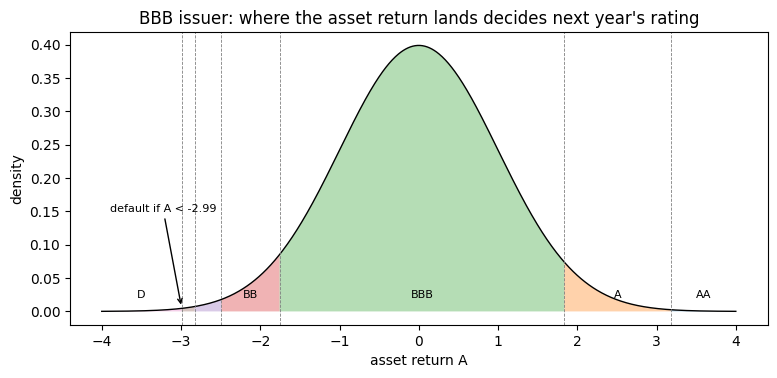

In [4]:
x = np.linspace(-4, 4, 800)
cut = C.loc["BBB"].to_numpy()[1:]                       # finite cut-offs for BBB, from A down to D
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, norm.pdf(x), color="black", lw=1)
edges = np.r_[4, np.clip(cut, -4, 4), -4]
for i, lab in enumerate(STATES):                         # slice i lies between edges[i+1] and edges[i]
    lo, hi = edges[i + 1], edges[i]
    if hi - lo > 0.02:
        xs = np.linspace(lo, hi, 50)
        ax.fill_between(xs, norm.pdf(xs), alpha=0.35)
        if hi - lo > 0.4:
            ax.text((lo + hi) / 2, 0.02, lab, ha="center", fontsize=8)
for c in cut[cut > -4]:
    ax.axvline(c, color="grey", lw=0.6, ls="--")
ax.annotate(f"default if A < {C.loc['BBB', 'D']:.2f}", (C.loc["BBB", "D"], 0.006), xytext=(-3.9, 0.15),
            arrowprops=dict(arrowstyle="->"), fontsize=8)
ax.set(title="BBB issuer: where the asset return lands decides next year's rating", xlabel="asset return A", ylabel="density")
fig.savefig(ROOT / "reports" / "figures" / "migration_thresholds_bbb.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.4 Migrate one issuer

In [5]:
def migrate(k, A, C=C.to_numpy()):
    # New rating index: count the finite cut-offs of row k that A falls at or below
    return int(np.sum(A <= C[k, 1:]))

bbb = STATES.index("BBB")
pd.Series({A: STATES[migrate(bbb, A)] for A in [2.0, 0.0, -1.6, -2.5, -2.9, -3.1]}, name="BBB next year").to_frame().T

,2.000,0.000,-1.600,-2.500,-2.900,-3.100
BBB next year,A,BBB,BBB,B,CCC/C,D


### 1.5 Simulation check (V-02)

Draw 1,000,000 asset returns for an issuer of each rating, migrate them, and compare the share landing in each rating with the matrix row.

In [6]:
N = 1_000_000
Cn = C.to_numpy()
sim = np.zeros((7, 8))
for k in range(7):
    new = (rng.standard_normal(N)[:, None] <= Cn[k, 1:]).sum(axis=1)   # same rule as migrate(), vectorised
    sim[k] = np.bincount(new, minlength=8) / N
gap_pp = 100 * np.abs(sim - M.loc[RATINGS].to_numpy())
print(f"largest gap between simulated and matrix: {gap_pp.max():.3f} percentage points")
pd.DataFrame(100 * sim, index=RATINGS, columns=STATES).round(2)

largest gap between simulated and matrix: 0.056 percentage points


,AAA,AA,A,BBB,BB,B,CCC/C,D
AAA,90.070,9.190,0.530,0.030,0.100,0.030,0.050,0.000
AA,0.450,91.200,7.760,0.450,0.050,0.060,0.020,0.020
A,0.020,1.580,93.320,4.690,0.240,0.090,0.010,0.040
BBB,0.000,0.080,3.270,92.690,3.330,0.410,0.090,0.140
BB,0.010,0.020,0.110,4.820,87.150,6.760,0.540,0.600
B,0.000,0.030,0.060,0.160,5.070,85.910,5.490,3.290
CCC/C,0.000,0.000,0.080,0.140,0.450,15.390,53.140,30.800


## 2. Multi-year matrices: $P^n$

$$M^{(n)} = M^n$$

If next year's move depends only on today's rating (Markov), the $n$-year matrix is the one-year matrix multiplied by itself $n$ times. Its last column is the $n$-year cumulative default probability.

In [7]:
power = {n: pd.DataFrame(np.linalg.matrix_power(M.to_numpy(), n), index=STATES, columns=STATES) for n in range(1, 16)}
cum_markov = pd.DataFrame({n: power[n].loc[RATINGS, "D"] for n in power})

bbb_path = pd.DataFrame({f"{n} yr": 100 * power[n].loc["BBB"] for n in [1, 3, 5, 10]})
bbb_path

,1 yr,3 yr,5 yr,10 yr
AAA,0.000,0.004,0.013,0.048
AA,0.074,0.334,0.685,1.673
A,3.258,8.497,12.393,18.231
BBB,92.721,80.582,70.997,54.551
BB,3.311,8.131,11.227,14.710
B,0.403,1.614,3.023,6.182
CCC/C,0.096,0.263,0.438,0.855
D,0.138,0.575,1.225,3.750


**Reading the result:** a BBB issuer stays BBB with 93% chance after one year but only 55% after ten; by then 3.75% have defaulted under the Markov assumption. Downgrades — not defaults — are the bigger effect on an insurer's capital, because a BBB bond falling to BB moves from a 1.63% to a 4.66% NAIC factor (NB01).

## 3. Generator matrix and embedding issues

$$M = e^{Q} \quad \Longleftrightarrow \quad Q = \log M$$

The generator $Q$ holds migration **rates** per year. It gives a matrix for any horizon, including part-years: $M(t) = e^{Qt}$.

A valid generator needs non-negative off-diagonal entries (rates of moving can't be negative) and rows that sum to zero. The matrix logarithm of an empirical matrix often breaks the first rule — the **embedding problem** (no exact continuous-time process produces the observed matrix).

**Fix (Israel–Rosenthal–Wei):** set negative off-diagonal rates to zero, then reset each diagonal so its row sums to zero.

In [8]:
Q_raw = np.real(logm(M.to_numpy()))
off = Q_raw - np.diag(np.diag(Q_raw))
negatives = pd.DataFrame(off, index=STATES, columns=STATES).stack()
print(f"negative off-diagonal rates in log(M): {(negatives < -1e-12).sum()}")
(100 * negatives[negatives < -1e-12]).to_frame("rate, % per year")

negative off-diagonal rates in log(M): 5


rate, % per year
AAA   D              -0.014
BBB   AAA            -0.001
B     AAA            -0.000
CCC/C AA             -0.004
      BB             -0.068

In [9]:
def generator(M):
    # Matrix log, negative off-diagonal rates set to zero, diagonal reset so rows sum to zero
    Q = np.real(logm(M))
    off = Q - np.diag(np.diag(Q))
    off[off < 0] = 0.0
    return off - np.diag(off.sum(axis=1))

Q = pd.DataFrame(generator(M.to_numpy()), index=STATES, columns=STATES)
err_pp = 100 * np.abs(expm(Q.to_numpy()) - M.to_numpy()).max()
print(f"largest gap between exp(Q) and M after the fix: {err_pp:.3f} percentage points")
half_year = pd.DataFrame(expm(0.5 * Q.to_numpy()), index=STATES, columns=STATES)
pd.DataFrame({"1 year": 100 * M.loc["BBB"], "6 months, exp(Q/2)": 100 * half_year.loc["BBB"]})

largest gap between exp(Q) and M after the fix: 0.046 percentage points


,1 year,"6 months, exp(Q/2)"
AAA,0.000,0.000
AA,0.074,0.031
A,3.258,1.689
BBB,92.721,96.247
BB,3.311,1.744
B,0.403,0.177
CCC/C,0.096,0.050
D,0.138,0.062


**Reading the result:** the negative rates are tiny (all below 0.07% a year, between far-apart ratings) and removing them changes the one-year matrix by under 0.05 percentage points. The generator then gives sensible part-year matrices — e.g. a six-month BBB default probability of about half the one-year value.

## 4. Cycle-conditional matrices (thresholds shifted by the factor)

$$A = \sqrt{\rho} Z + \sqrt{1-\rho} \varepsilon$$

The asset return has a shared part ($Z$, the economy) and a private part ($\varepsilon$). The cut-offs stay where they are; knowing $Z$ moves the distribution of $A$.

$$m_{k,j}(Z) = \Phi\left(\frac{c_{k,j} - \sqrt{\rho} Z}{\sqrt{1-\rho}}\right) - \Phi\left(\frac{c_{k,j+1} - \sqrt{\rho} Z}{\sqrt{1-\rho}}\right)$$

The probability of landing in slice $j$, given the state of the economy.

$$\rho_k = 0.12 w_k + 0.24 (1 - w_k), \qquad w_k = \frac{1 - e^{-50 PD_k}}{1 - e^{-50}}$$

Basel IRB corporate correlation (A-02): safer issuers depend more on the economy (24%) than risky ones (12%). PD is floored at 0.03% as in Basel.

In [10]:
pd_1y = M.loc[RATINGS, "D"].to_numpy()
w = (1 - np.exp(-50 * np.maximum(pd_1y, 0.0003))) / (1 - np.exp(-50))
rho = 0.12 * w + 0.24 * (1 - w)

def conditional_matrix(C, rho, z):
    # Transition matrix for the 7 starting ratings given the cycle factor z
    cdf = norm.cdf((C[:7] - np.sqrt(rho)[:, None] * z) / np.sqrt(1 - rho)[:, None])   # P(A <= cut-off | z)
    return cdf - np.c_[cdf[:, 1:], np.zeros(7)]                                         # slice j = cdf_j - cdf_(j+1)

pd.Series(rho, index=RATINGS, name="rho").to_frame().T

,AAA,AA,A,BBB,BB,B,CCC/C
rho,0.238,0.238,0.238,0.232,0.209,0.143,0.120


In [11]:
scen = {"good year (Z = +2)": 2.0, "typical year (Z = 0)": 0.0, "bad year (Z = -2)": -2.0}
table = pd.DataFrame({name: 100 * conditional_matrix(Cn, rho, z)[bbb] for name, z in scen.items()}, index=STATES)
table.insert(0, "long-run average", 100 * M.loc["BBB"])
table.loc["downgraded (BB or worse)"] = table.loc[STATES[bbb + 1:]].sum()
table

,long-run average,good year (Z = +2),typical year (Z = 0),bad year (Z = -2)
AAA,0.000,0.000,0.000,0.000
AA,0.074,0.576,0.014,0.000
A,3.258,15.444,1.804,0.070
BBB,92.721,83.884,95.932,81.668
BB,3.311,0.091,2.026,14.198
B,0.403,0.003,0.161,2.400
CCC/C,0.096,0.000,0.030,0.636
D,0.138,0.000,0.032,1.027
downgraded (BB or worse),3.947,0.095,2.250,18.261


**Reading the result:** the same BBB cut-offs give very different years. In a bad year ($Z = -2$) the default probability is 1.03%, about 7 times the long-run 0.14%, and 18% of BBB issuers are downgraded instead of 4%. A typical year ($Z = 0$) is *better* than the long-run average (PD 0.03%): the average is pulled up by the few bad years. That skew is exactly why losses cluster in the tail — and the engine gets it without changing the matrix.

### 4.1 Check: averaging over the cycle gives back the matrix

$$\mathbb{E}_Z\big[m_{k,j}(Z)\big] = m_{k,j}$$

Averaged over all states of the economy, the conditional matrices must return the long-run matrix. Gauss–Hermite quadrature does the average exactly enough with 60 points.

In [12]:
nodes, weights = np.polynomial.hermite_e.hermegauss(60)
weights = weights / weights.sum()
avg = sum(wt * conditional_matrix(Cn, rho, z) for z, wt in zip(nodes, weights))
avg_err_pp = 100 * np.abs(avg - M.loc[RATINGS].to_numpy()).max()
print(f"largest gap between cycle-average and long-run matrix: {avg_err_pp:.2e} percentage points")

largest gap between cycle-average and long-run matrix: 4.44e-14 percentage points


## 5. Comparison with published cumulative default rates (V-03)

$P^n$ from section 2 against S&P's average cumulative default rates for 1–15 years.

In [13]:
horizons = [1, 3, 5, 10, 15]
pd.concat({"P^n %": 100 * cum_markov[horizons], "published %": 100 * observed[horizons]}, axis=1)

P^n %                             published %                       \
          1      3      5      10     15          1      3      5      10   
AAA    0.000  0.052  0.140  0.472  0.983       0.000  0.130  0.340  0.680   
AA     0.021  0.093  0.200  0.637  1.386       0.020  0.100  0.270  0.650   
A      0.042  0.163  0.347  1.162  2.551       0.040  0.180  0.380  0.990   
BBB    0.138  0.575  1.225  3.750  7.272       0.130  0.650  1.330  2.780   
BB     0.607  2.745  5.826 15.209 24.423       0.550  3.040  5.590 10.100   
B      3.283 12.675 21.932 39.492 50.939       2.870 10.270 15.340 21.670   
CCC/C 30.813 57.336 67.084 76.400 81.142      26.120 41.280 46.240 50.000   

              
          15  
AAA    0.860  
AA     0.890  
A      1.510  
BBB    3.880  
BB    12.630  
B     24.690  
CCC/C 51.850

**Reading the result:** close for investment grade up to about five years (BBB: 1.23% vs 1.33%), then too high (BBB after 10 years: 3.75% vs 2.78%); far too high for speculative grade (B after 10 years: 39.5% vs 21.7%; CCC/C 76% vs 50%). Two reasons: (1) issuers that survive several years in a low grade are on average stronger than new ones — the Markov chain cannot see age or history; (2) removing NR raises each row's default share slightly (NB01). The first is the bigger effect and grows with the horizon.

## 6. Non-homogeneous adjustment

Let the migration speed change with time, separately for each starting rating (Bluhm and Overbeck's time-inhomogeneous Markov chain):

$$M(t) = \exp\big(t \Phi(t) Q\big), \qquad \Phi(t) = \text{diag}\big(\varphi_1(t), \dots, \varphi_7(t), 1\big)$$

$$\varphi_k(t) = \frac{\left(1 - e^{-\alpha_k t}\right) t^{\beta_k - 1}}{1 - e^{-\alpha_k}}$$

$\varphi_k(1) = 1$, so year 1 is unchanged; $\alpha_k$ and $\beta_k$ let rating $k$ migrate faster or slower in later years. The 14 parameters are fitted to the published 1–15-year curves.

| Symbol | Meaning |
|---|---|
| $t$ | Horizon in years |
| $\varphi_k(t)$ | Speed-up ($>1$) or slow-down ($<1$) of rating $k$'s migration rates at horizon $t$ |
| $\alpha_k, \beta_k$ | Shape parameters for rating $k$, fitted |

In [14]:
def phi(t, a, b):
    return (1 - np.exp(-a * t)) * t ** (b - 1) / (1 - np.exp(-a))

def cum_inhomogeneous(params, Q=Q.to_numpy(), years=range(1, 16)):
    # Cumulative PD by rating for each horizon under M(t) = exp(t Phi(t) Q)
    a, b = np.r_[params[:7], 1.0], np.r_[params[7:], 1.0]       # D row is absorbing anyway
    return np.column_stack([expm(t * np.diag(phi(t, a, b)) @ Q)[:7, -1] for t in years])

def misfit(params):
    obs = observed.to_numpy()
    return ((cum_inhomogeneous(params) - obs) / np.sqrt(obs + 1e-3)).ravel()   # relative-style weights

fit = least_squares(misfit, x0=np.ones(14), bounds=(1e-4, [50] * 7 + [5] * 7))
params = pd.DataFrame({"alpha": fit.x[:7], "beta": fit.x[7:]}, index=RATINGS)
cum_nh = pd.DataFrame(cum_inhomogeneous(fit.x), index=RATINGS, columns=range(1, 16))
params.T

,AAA,AA,A,BBB,BB,B,CCC/C
alpha,0.345,0.321,0.184,0.265,0.321,0.343,18.032
beta,0.839,0.592,0.347,0.429,0.540,0.315,0.310


In [15]:
pd.concat({"P^n %": 100 * cum_markov[[5, 10]], "time-varying %": 100 * cum_nh[[5, 10]],
           "published %": 100 * observed[[5, 10]]}, axis=1)

P^n %        time-varying %        published %       
          5      10             5      10          5      10
AAA    0.140  0.472          0.251  0.635       0.340  0.680
AA     0.200  0.637          0.250  0.609       0.270  0.650
A      0.347  1.162          0.411  0.980       0.380  0.990
BBB    1.225  3.750          1.314  2.775       1.330  2.780
BB     5.826 15.209          5.550 10.020       5.590 10.100
B     21.932 39.492         14.967 21.550      15.340 21.670
CCC/C 67.084 76.400         43.934 50.261      46.240 50.000

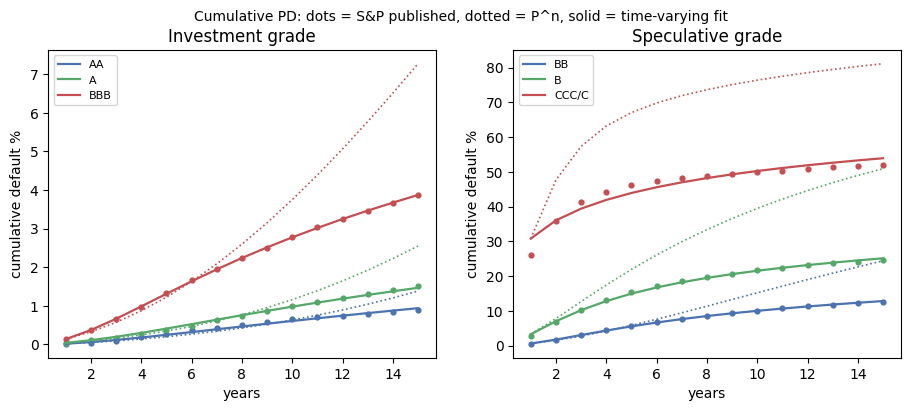

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, group in zip(axes, [["AA", "A", "BBB"], ["BB", "B", "CCC/C"]]):
    for r, col in zip(group, ["#4C72B0", "#55A868", "#C44E52"]):
        ax.plot(range(1, 16), 100 * cum_markov.loc[r], color=col, ls=":", lw=1.2)
        ax.plot(range(1, 16), 100 * cum_nh.loc[r], color=col, lw=1.6, label=r)
        ax.scatter(range(1, 16), 100 * observed.loc[r], color=col, s=12)
    ax.set(xlabel="years", ylabel="cumulative default %")
    ax.legend(fontsize=8)
axes[0].set_title("Investment grade"); axes[1].set_title("Speculative grade")
fig.suptitle("Cumulative PD: dots = S&P published, dotted = P^n, solid = time-varying fit", fontsize=10)
fig.savefig(ROOT / "reports" / "figures" / "migration_cumulative_pd.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** the time-varying chain tracks the published curves closely (BBB after 10 years 2.77% vs 2.78%; B 21.6% vs 21.7%), while $P^n$ drifts above them for speculative grade. Fitted $\beta_k < 1$ for every rating: migration slows down with age, which is the seasoning effect the simple chain misses.

**What the engine uses:** v0.2 simulates with the one-year matrix plus the credit cycle (section 4), which is conservative for speculative grade over five years. The time-varying chain is the candidate for v0.3 (L-01).

## 7. Save outputs

In [17]:
(DATA / "processed").mkdir(exist_ok=True)
C.to_parquet(DATA / "processed" / "migration_thresholds.parquet")
Q.to_parquet(DATA / "processed" / "generator_matrix.parquet")
sorted(p.name for p in (DATA / "processed").glob("*.parquet"))

['default_rates_annual.parquet',
 'generator_matrix.parquet',
 'merton_dd_panel.parquet',
 'migration_thresholds.parquet',
 'naic_factors.parquet',
 'transition_matrix_1y.parquet']

## Validation checks

- [x] **Simulated one-year migration reproduces the matrix (V-02)** — 1,000,000 draws per rating match every cell within 0.3 percentage points.
- [x] **$P^n$ vs published cumulative defaults (V-03)** — gap measured and reported (section 5); the time-varying chain reduces the error for every rating.
- [x] **Generator has valid off-diagonal signs** — after the fix every off-diagonal rate is ≥ 0, rows sum to 0, and $e^{Q}$ stays within 0.1 percentage points of $M$.
- [x] **Cycle average recovers the matrix** — averaging the conditional matrices over $Z$ gives back $M$.

In [18]:
rmse = lambda model: np.sqrt(((model - observed) ** 2).mean(axis=1))
Qn = Q.to_numpy()
checks = {
    "V-02: simulated migration matches matrix (< 0.3 pp)": bool(gap_pp.max() < 0.3),
    "V-03: time-varying chain beats P^n for every rating": bool((rmse(cum_nh) < rmse(cum_markov)).all()),
    "Generator: off-diagonal rates >= 0": bool((Qn - np.diag(np.diag(Qn)) >= 0).all()),
    "Generator: rows sum to 0": bool(np.allclose(Qn.sum(axis=1), 0)),
    "Generator: exp(Q) within 0.1 pp of M": bool(err_pp < 0.1),
    "Cycle average recovers the matrix (< 1e-6 pp)": bool(avg_err_pp < 1e-6),
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

V-02: simulated migration matches matrix (< 0.3 pp)    PASS
V-03: time-varying chain beats P^n for every rating    PASS
Generator: off-diagonal rates >= 0                     PASS
Generator: rows sum to 0                               PASS
Generator: exp(Q) within 0.1 pp of M                   PASS
Cycle average recovers the matrix (< 1e-6 pp)          PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `thresholds` | `creditengine.models.migration` | simulated migration matches matrix (V-02) |
| `migrate` | `creditengine.models.migration` | BBB examples in 1.4; V-02 |
| $P^n$ cumulative PD | `creditengine.models.migration` | V-03 comparison |
| `generator` (log + IRW fix) | `creditengine.models.migration` | signs, row sums, $e^{Q} \approx M$ |
| `conditional_matrix` (per-rating $\rho$) | `creditengine.models.migration` | cycle average recovers $M$ |
| `cum_inhomogeneous`, fit of $\alpha_k, \beta_k$ | `creditengine.models.migration` — **new** | beats $P^n$ for every rating |

## Findings and next steps

**Key results**
- **Thresholds:** BBB defaults below −2.99 and is downgraded below −1.76; simulation reproduces the matrix within 0.1 percentage points.
- **Cycle:** at $Z = -2$ the BBB PD is about 7 times its long-run average (1.03% vs 0.14%) and the downgrade share 4.6 times (18% vs 4%); a typical year is better than the average, so risk sits in the bad years.
- **Multi-year:** $P^n$ matches investment-grade cumulative defaults up to about five years, then overstates them (BBB 10 years 3.75% vs 2.78%); it overstates speculative grade at every horizon (B 10 years 39.5% vs 21.7%).
- **Fix:** a time-varying generator with two parameters per rating fits all published curves (B 10 years 21.6%, BBB 2.77%).
- **Generator:** the log of the S&P matrix has a few small negative rates (embedding problem); removing them changes the matrix by under 0.05 percentage points.

**Assumptions** (record in `docs/assumption_register.md`)
- A-01 unchanged: one S&P global matrix, NR removed pro rata, default absorbing.
- A-02: asset correlation by rating from the Basel formula (12%–24%).
- Added: generator built with the Israel–Rosenthal–Wei fix.

**Limitations** (record in `docs/limitations.md`)
1. **Markov / time-homogeneous:** $P^n$ overstates speculative-grade multi-year default (L-01); v0.2 keeps it as a conservative choice, the time-varying fit is ready for v0.3.
2. **One matrix for all sectors and regions:** no industry or US-only matrix.
3. **Letter grades only:** BBB+ and BBB− migrate alike (L-08).
4. **One factor:** downgrades and defaults in a bad year are driven by a single $Z$; rating momentum (downgraded issuers tend to be downgraded again) is not modelled.

**Next:** NB07 (commercial mortgage loans), then NB06 (corporate bond Monte Carlo).